In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("C:\\Users\\DELL\\Downloads\\35. sales_data.csv")

In [4]:
df.head()

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,1/6/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,1/8/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,1/5/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,1/5/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,1/8/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011


In [5]:
df.shape

(51290, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        51290 non-null  object 
 1   order_date      51290 non-null  object 
 2   ship_date       51290 non-null  object 
 3   ship_mode       51290 non-null  object 
 4   customer_name   51290 non-null  object 
 5   segment         51290 non-null  object 
 6   state           51290 non-null  object 
 7   country         51290 non-null  object 
 8   market          51290 non-null  object 
 9   region          51290 non-null  object 
 10  product_id      51290 non-null  object 
 11  category        51290 non-null  object 
 12  sub_category    51290 non-null  object 
 13  product_name    51290 non-null  object 
 14  sales           51290 non-null  object 
 15  quantity        51290 non-null  int64  
 16  discount        51290 non-null  float64
 17  profit          51290 non-null 

In [7]:
df.isna().sum()

order_id          0
order_date        0
ship_date         0
ship_mode         0
customer_name     0
segment           0
state             0
country           0
market            0
region            0
product_id        0
category          0
sub_category      0
product_name      0
sales             0
quantity          0
discount          0
profit            0
shipping_cost     0
order_priority    0
year              0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_name',
       'segment', 'state', 'country', 'market', 'region', 'product_id',
       'category', 'sub_category', 'product_name', 'sales', 'quantity',
       'discount', 'profit', 'shipping_cost', 'order_priority', 'year'],
      dtype='object')

In [10]:
df["sales"] = pd.to_numeric(
    df["sales"].astype(str).str.replace(",", "")
)

df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

In [11]:
df.dtypes

order_id                  object
order_date        datetime64[ns]
ship_date         datetime64[ns]
ship_mode                 object
customer_name             object
segment                   object
state                     object
country                   object
market                    object
region                    object
product_id                object
category                  object
sub_category              object
product_name              object
sales                      int64
quantity                   int64
discount                 float64
profit                   float64
shipping_cost            float64
order_priority            object
year                       int64
dtype: object

In [12]:
(df["ship_date"] < df["order_date"]).sum()

np.int64(0)

In [13]:
df[["sales", "quantity", "discount", "profit", "shipping_cost"]].describe()

,sales,quantity,discount,profit,shipping_cost
count,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,246.498440,3.476545,0.142908,28.641740,26.375915
std,487.567175,2.278766,0.212280,174.424113,57.296804
min,0.000000,1.000000,0.000000,-6599.978000,0.000000
25%,31.000000,2.000000,0.000000,0.000000,2.610000
50%,85.000000,3.000000,0.000000,9.240000,7.790000
75%,251.000000,5.000000,0.200000,36.810000,24.450000
max,22638.000000,14.000000,0.850000,8399.976000,933.570000


In [14]:
df[["segment", "ship_mode", "market", "region", "category", "sub_category"]].nunique()

segment          3
ship_mode        4
market           7
region          13
category         3
sub_category    17
dtype: int64

In [15]:
print("Total Sales:", df["sales"].sum())
print("Total Profit:", df["profit"].sum())
print("Total Orders:", df["order_id"].nunique())
print("Average Order Value:", df["sales"].mean())

Total Sales: 12642905
Total Profit: 1469034.82128
Total Orders: 25035
Average Order Value: 246.49844024176252


In [16]:
print("Profitable Records:", (df["profit"] > 0).sum())
print("Loss-Making Records:", (df["profit"] < 0).sum())

Profitable Records: 38079
Loss-Making Records: 12543


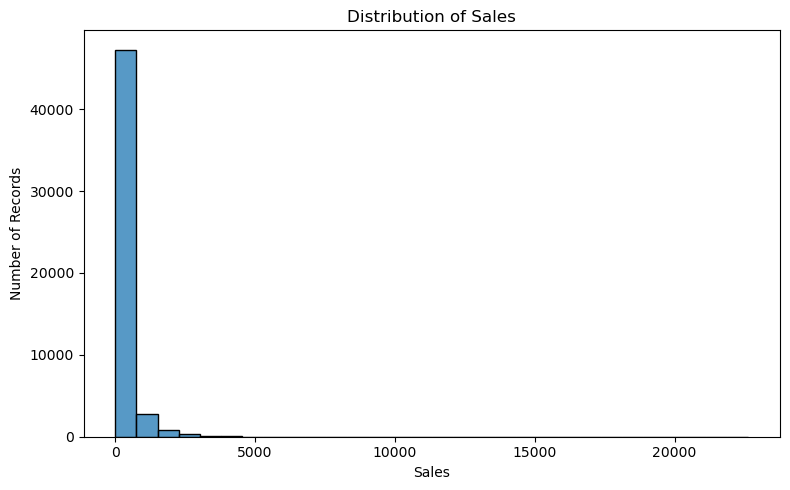

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(df["sales"], bins=30)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

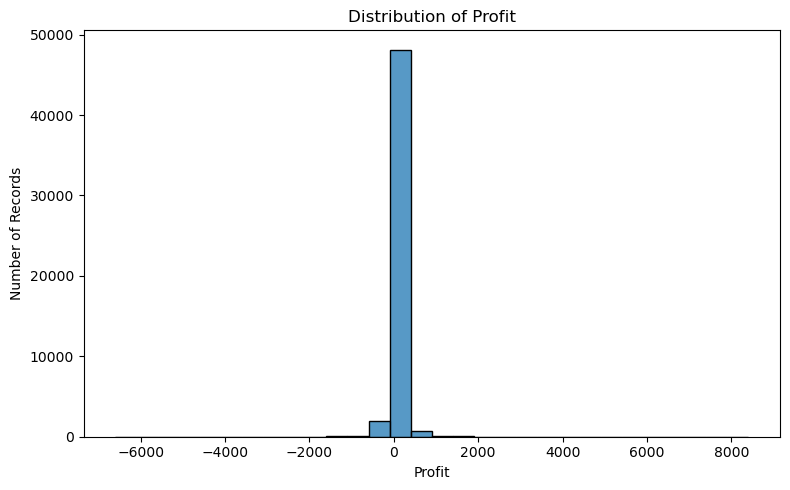

In [18]:
plt.figure(figsize=(8,5))
sns.histplot(df["profit"], bins=30)
plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

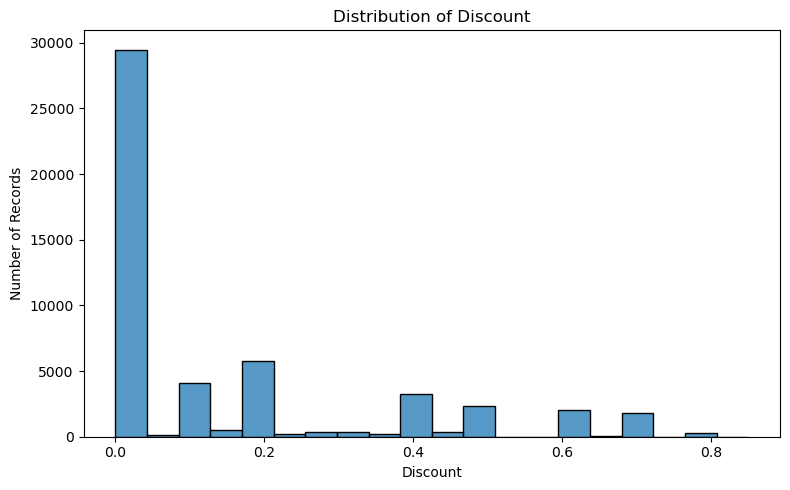

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(df["discount"], bins=20)
plt.title("Distribution of Discount")
plt.xlabel("Discount")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

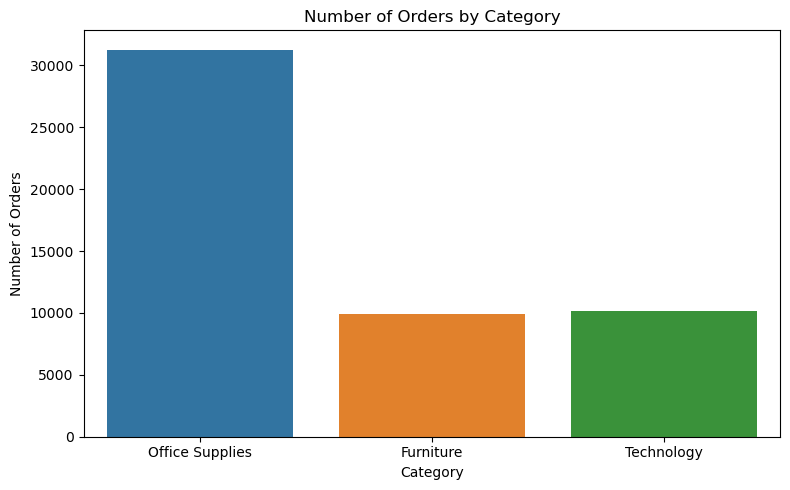

In [20]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="category", hue="category", legend=False)
plt.title("Number of Orders by Category")
plt.xlabel("Category")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

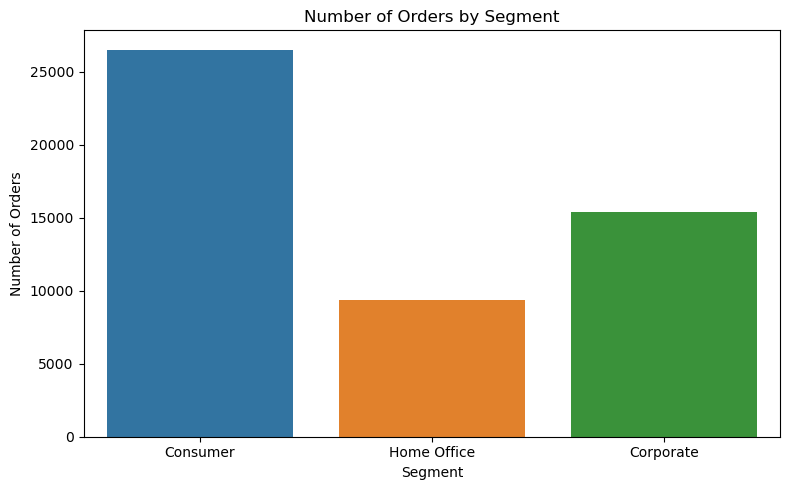

In [21]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="segment", hue="segment", legend=False)
plt.title("Number of Orders by Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

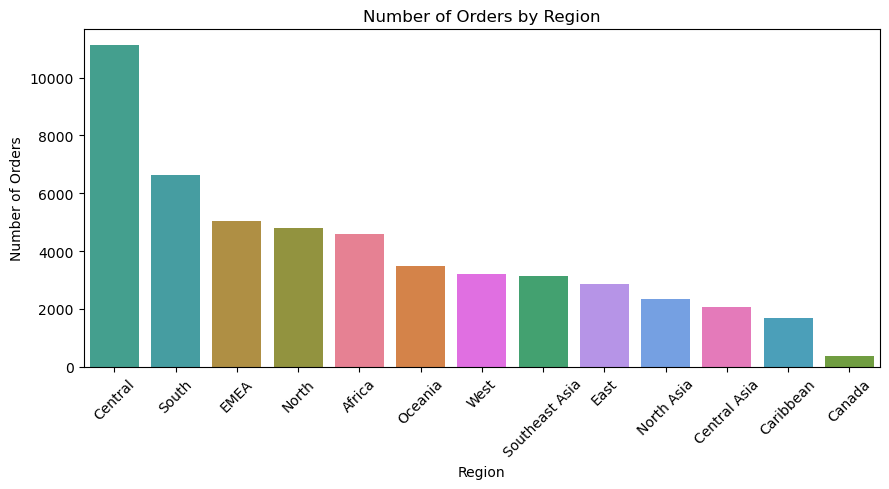

In [22]:
plt.figure(figsize=(9,5))
sns.countplot(
    data=df,
    x="region",
    order=df["region"].value_counts().index,
    hue="region",
    legend=False
)
plt.title("Number of Orders by Region")
plt.xlabel("Region")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

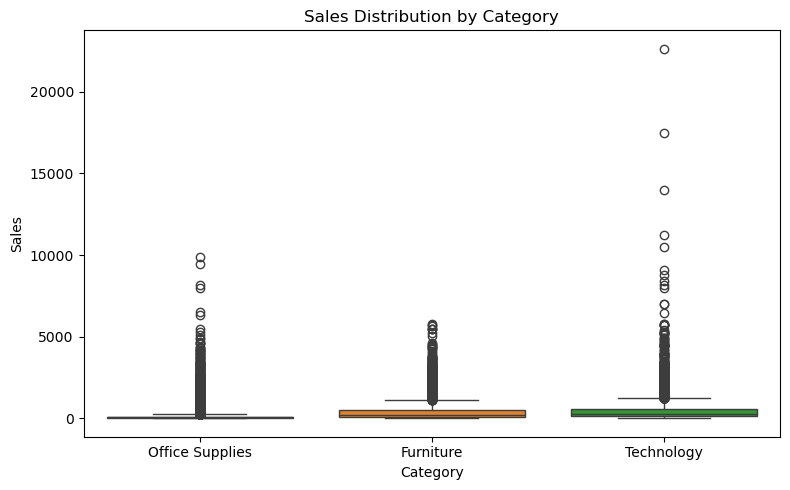

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="category",
    y="sales",
    hue="category",
    legend=False
)

plt.title("Sales Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

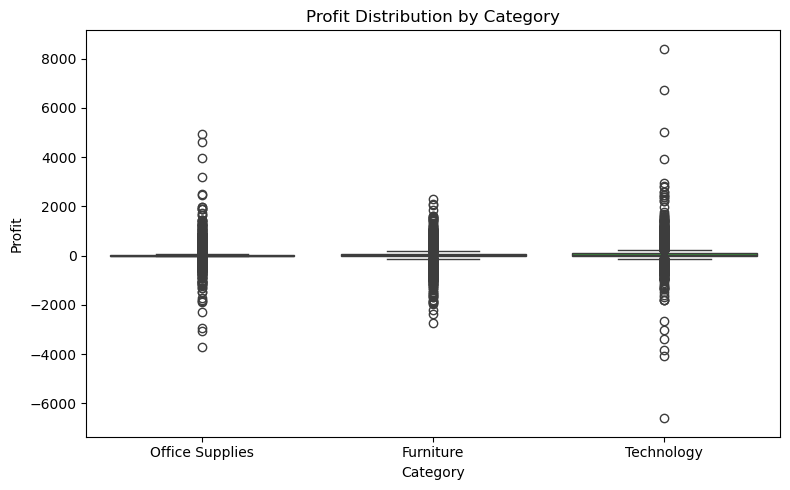

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="category",
    y="profit",
    hue="category",
    legend=False
)

plt.title("Profit Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

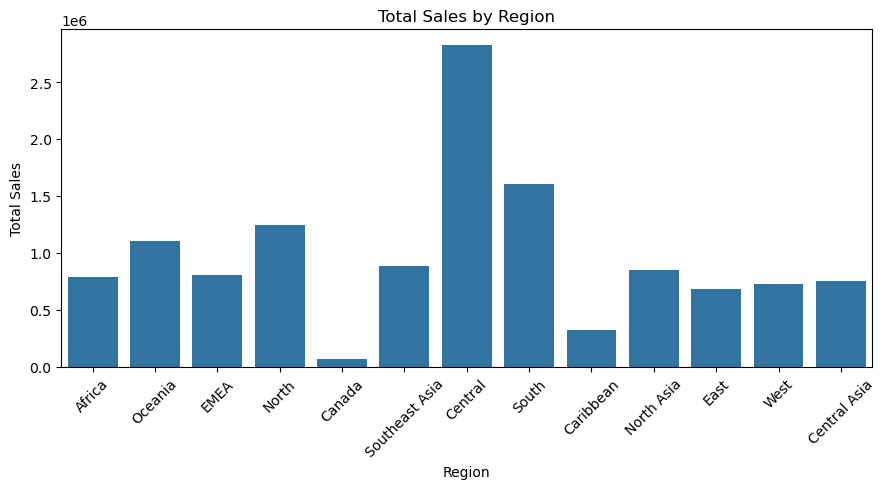

In [25]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df,
    x="region",
    y="sales",
    estimator="sum",
    errorbar=None
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

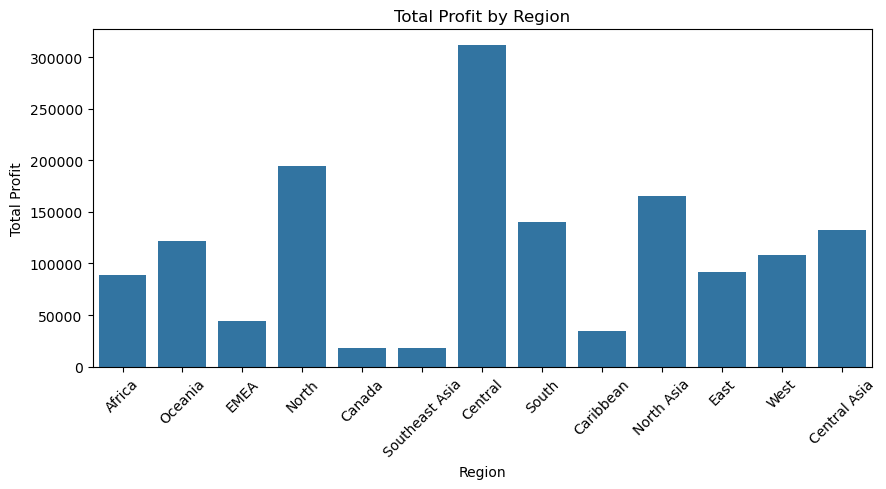

In [26]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df,
    x="region",
    y="profit",
    estimator="sum",
    errorbar=None
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

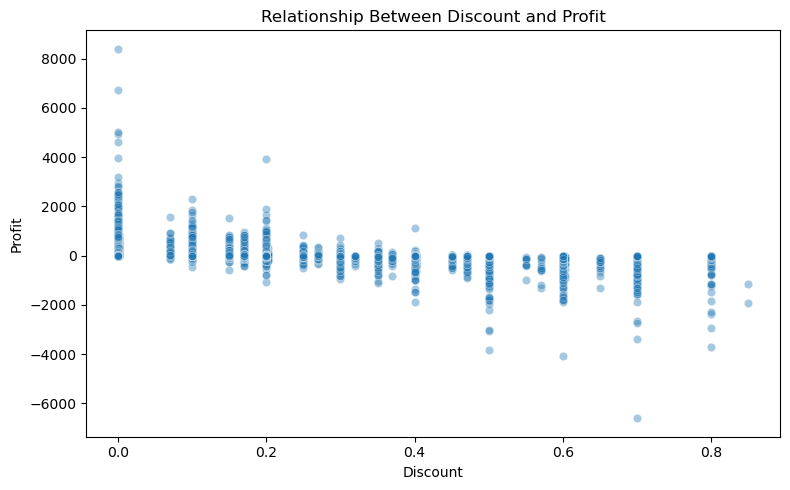

In [27]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    alpha=0.4
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

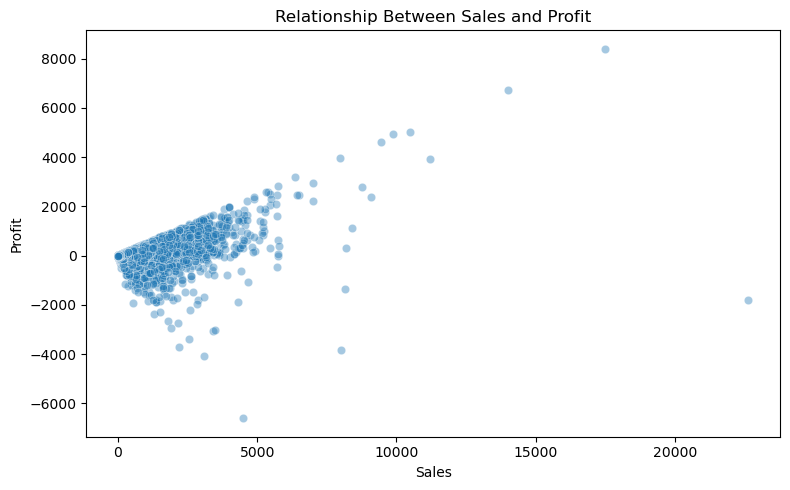

In [28]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="sales",
    y="profit",
    alpha=0.4
)

plt.title("Relationship Between Sales and Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

In [29]:
category_analysis = df.groupby("category").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    avg_sales=("sales", "mean"),
    avg_profit=("profit", "mean")
).sort_values("total_sales", ascending=False)

category_analysis

,total_sales,total_profit,avg_sales,avg_profit
category,,,,
Technology,4744691,663778.73318,467.872103,65.454958
Furniture,4110884,286782.25380,416.249899,29.038300
Office Supplies,3787330,518473.83430,121.105426,16.578961


In [30]:
region_analysis = df.groupby("region").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    avg_sales=("sales", "mean"),
    avg_profit=("profit", "mean")
).sort_values("total_sales", ascending=False)

region_analysis

,total_sales,total_profit,avg_sales,avg_profit
region,,,,
Central,2822399,311403.98164,253.881353,28.011512
South,1600960,140355.76618,240.927013,21.122011
North,1248192,194597.95252,260.855172,40.668329
Oceania,1100207,121666.64200,315.516777,34.891495
Southeast Asia,884438,17852.32900,282.658357,5.705442
North Asia,848349,165578.42100,362.852438,70.820539
EMEA,806184,43897.97100,160.307019,8.728966
Africa,783776,88871.63100,170.868978,19.374674
Central Asia,752839,132480.18700,367.597168,64.687591


In [31]:
subcategory_analysis = df.groupby("sub_category").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
).sort_values("total_profit", ascending=False)

subcategory_analysis.head(10)

,total_sales,total_profit
sub_category,,
Copiers,1509439,258567.54818
Phones,1706874,216717.00580
Bookcases,1466559,161924.41950
Chairs,1501682,141973.79750
Appliances,1011081,141680.58940
Accessories,749307,129626.30620
Storage,1127124,108461.48980
Binders,461952,72449.84600
Paper,244307,59207.68270


In [32]:
product_analysis = df.groupby("product_name").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
).sort_values("total_sales", ascending=False)

product_analysis.head(10)

,total_sales,total_profit
product_name,,
"Apple Smart Phone, Full Size",86936,5921.5786
"Cisco Smart Phone, Full Size",76441,17238.5206
"Motorola Smart Phone, Full Size",73159,17027.1130
"Nokia Smart Phone, Full Size",71904,9938.1955
Canon imageCLASS 2200 Advanced Copier,61600,25199.9280
"Hon Executive Leather Armchair, Adjustable",58200,5997.2541
"Office Star Executive Leather Armchair, Adjustable",50667,4710.9840
"Harbour Creations Executive Leather Armchair, Adjustable",50120,10427.3260
"Samsung Smart Phone, Cordless",48654,-198.0900


In [33]:
subcategory_analysis.sort_values("total_profit").head(10)

,total_sales,total_profit
sub_category,,
Tables,757034,-64083.3887
Fasteners,83254,11525.4241
Labels,73433,15010.5120
Supplies,243090,22583.2631
Envelopes,170926,29601.1163
Furnishings,385609,46967.4255
Art,372163,57953.9109
Machines,779071,58867.8730
Paper,244307,59207.6827


In [34]:
df["month"] = df["order_date"].dt.to_period("M")

monthly_sales = df.groupby("month")["sales"].sum()

monthly_sales

month
2011-01     98902
2011-02     91152
2011-03    145726
2011-04    116927
2011-05    146762
2011-06    215214
2011-07    115518
2011-08    207570
2011-09    290230
2011-10    199070
2011-11    298499
2011-12    333941
2012-01    135775
2012-02    100521
2012-03    163092
2012-04    161060
2012-05    208370
2012-06    256181
2012-07    145247
2012-08    303158
2012-09    289390
2012-10    252942
2012-11    323512
2012-12    338245
2013-01    199197
2013-02    167247
2013-03    198591
2013-04    177835
2013-05    260525
2013-06    396513
2013-07    229940
2013-08    326491
2013-09    376626
2013-10    293423
2013-11    373996
2013-12    405476
2014-01    241267
2014-02    184848
2014-03    263110
2014-04    242781
2014-05    288404
2014-06    401843
2014-07    258718
2014-08    456633
2014-09    481186
2014-10    422785
2014-11    555312
2014-12    503154
Freq: M, Name: sales, dtype: int64

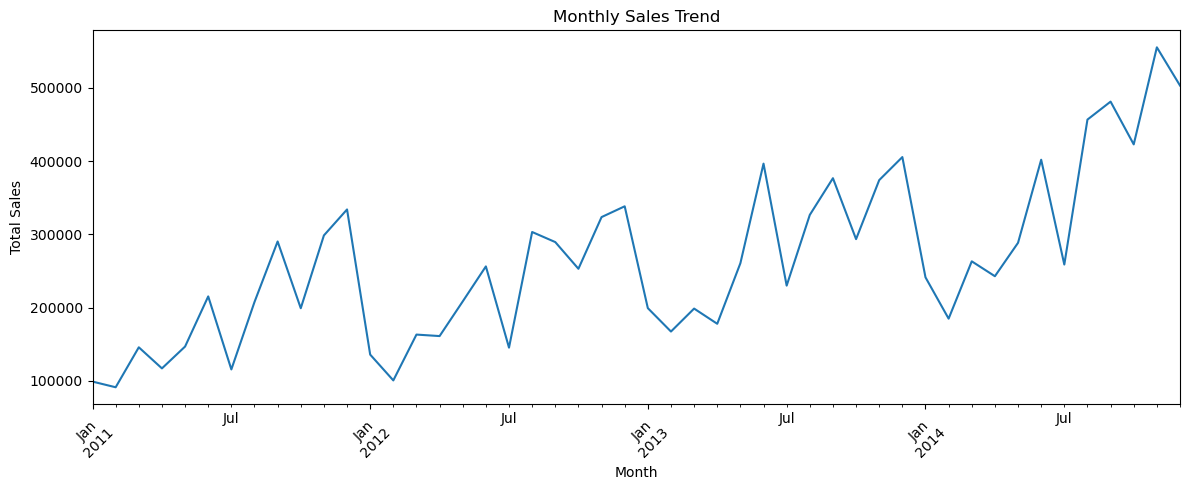

In [35]:
plt.figure(figsize=(12,5))

monthly_sales.plot()

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [36]:
df.shape

(51290, 22)

In [37]:
df.head()

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year,month
0,AG-2011-2040,2011-01-01,2011-01-06,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Storage,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011,2011-01
1,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Supplies,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011,2011-01
2,HU-2011-1220,2011-01-01,2011-01-05,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Storage,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011,2011-01
3,IT-2011-3647632,2011-01-01,2011-01-05,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Paper,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011,2011-01
4,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011,2011-01


In [38]:
df["profit_margin"] = (df["profit"] / df["sales"]) * 100

In [39]:
df["profit_margin"].describe()

count    5.129000e+04
mean             -inf
std               NaN
min              -inf
25%      0.000000e+00
50%      1.692552e+01
75%      3.331303e+01
max      5.828000e+01
Name: profit_margin, dtype: float64

In [40]:
margin_analysis = df.groupby("category").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    profit_margin=("profit_margin", "mean")
).sort_values("profit_margin", ascending=False)

margin_analysis

,total_sales,total_profit,profit_margin
category,,,
Technology,4744691,663778.73318,4.965838
Furniture,4110884,286782.25380,0.874818
Office Supplies,3787330,518473.83430,-inf


In [41]:
discount_analysis = df.groupby("discount").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
).sort_values("discount")

discount_analysis

,total_sales,total_profit
discount,,
0.000,6992734,1.770695e+06
0.002,261395,5.797658e+04
0.070,121620,2.114850e+04
0.100,1579618,2.606417e+05
0.150,306037,2.737590e+04
0.170,247404,2.816307e+04
0.200,1203855,1.177159e+05
0.202,16213,-5.952727e+02
0.250,88063,8.005875e+02


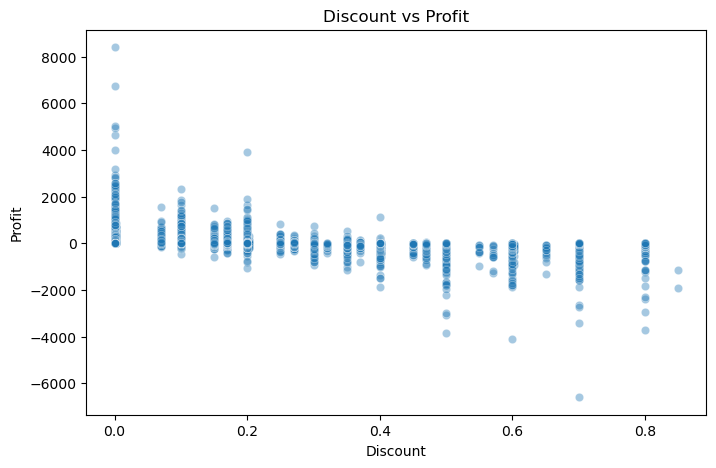

In [42]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="discount", y="profit", alpha=0.4)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

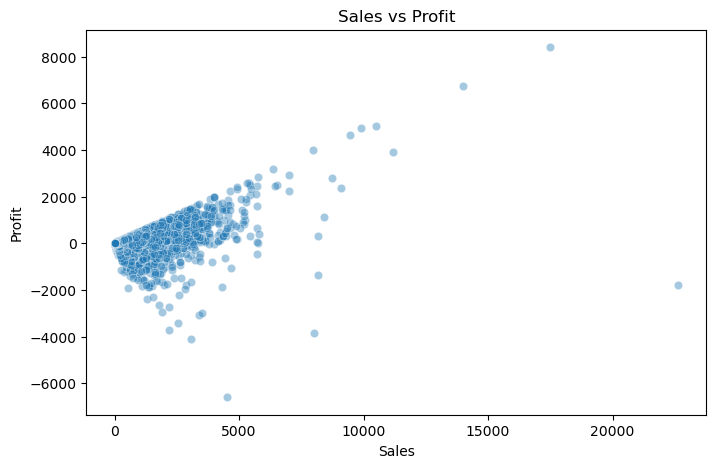

In [43]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="sales", y="profit", alpha=0.4)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

In [44]:
df["month"] = df["order_date"].dt.to_period("M")

monthly_sales = df.groupby("month")["sales"].sum()

monthly_sales

month
2011-01     98902
2011-02     91152
2011-03    145726
2011-04    116927
2011-05    146762
2011-06    215214
2011-07    115518
2011-08    207570
2011-09    290230
2011-10    199070
2011-11    298499
2011-12    333941
2012-01    135775
2012-02    100521
2012-03    163092
2012-04    161060
2012-05    208370
2012-06    256181
2012-07    145247
2012-08    303158
2012-09    289390
2012-10    252942
2012-11    323512
2012-12    338245
2013-01    199197
2013-02    167247
2013-03    198591
2013-04    177835
2013-05    260525
2013-06    396513
2013-07    229940
2013-08    326491
2013-09    376626
2013-10    293423
2013-11    373996
2013-12    405476
2014-01    241267
2014-02    184848
2014-03    263110
2014-04    242781
2014-05    288404
2014-06    401843
2014-07    258718
2014-08    456633
2014-09    481186
2014-10    422785
2014-11    555312
2014-12    503154
Freq: M, Name: sales, dtype: int64

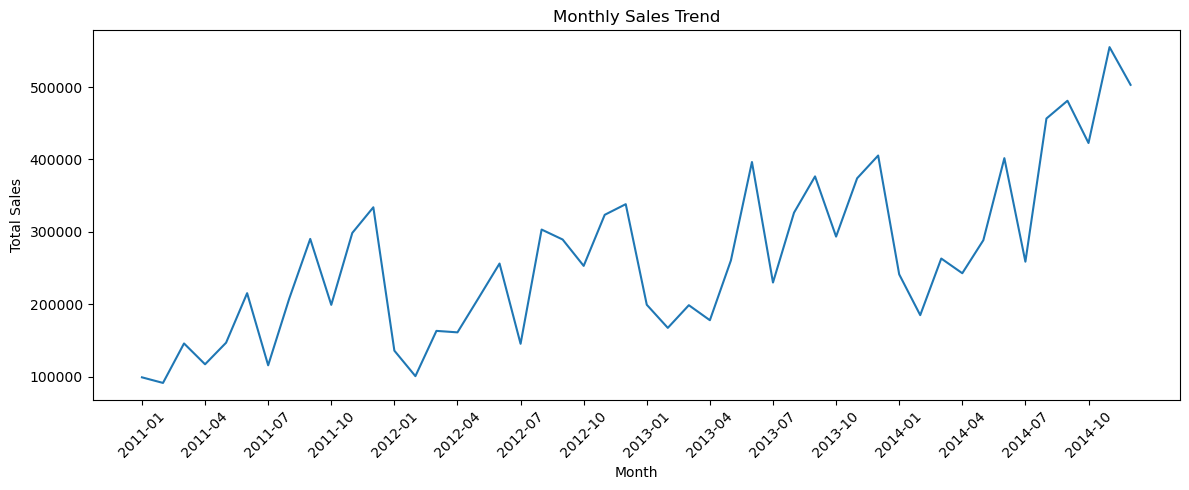

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index.astype(str), monthly_sales.values)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(
    range(0, len(monthly_sales), 3),
    monthly_sales.index.astype(str)[::3],
    rotation=45
)

plt.tight_layout()
plt.show()

In [46]:
top_profit_products = df.groupby("product_name").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
).sort_values("total_profit", ascending=False)

top_profit_products.head(10)

,total_sales,total_profit
product_name,,
Canon imageCLASS 2200 Advanced Copier,61600,25199.9280
"Cisco Smart Phone, Full Size",76441,17238.5206
"Motorola Smart Phone, Full Size",73159,17027.1130
"Hoover Stove, Red",31664,11807.9690
"Sauder Classic Bookcase, Traditional",39110,10672.0730
"Harbour Creations Executive Leather Armchair, Adjustable",50120,10427.3260
"Nokia Smart Phone, Full Size",71904,9938.1955
"Cisco Smart Phone, with Caller ID",43124,9786.6408
"Nokia Smart Phone, with Caller ID",47880,9465.3257


In [47]:
bottom_profit_products = top_profit_products.sort_values("total_profit").head(10)

bottom_profit_products

,total_sales,total_profit
product_name,,
Cubify CubeX 3D Printer Double Head Print,11100,-8879.9704
Lexmark MX611dhe Monochrome Laser Printer,16830,-4589.9730
"Motorola Smart Phone, Cordless",38935,-4447.0380
Cubify CubeX 3D Printer Triple Head Print,8000,-3839.9904
"Bevis Round Table, Adjustable Height",5655,-3649.8940
"Bevis Computer Table, Fully Assembled",11176,-3509.5638
"Rogers Lockers, Blue",28215,-2893.4908
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9918,-2876.1156
"Bevis Wood Table, with Bottom Storage",11134,-2782.5880


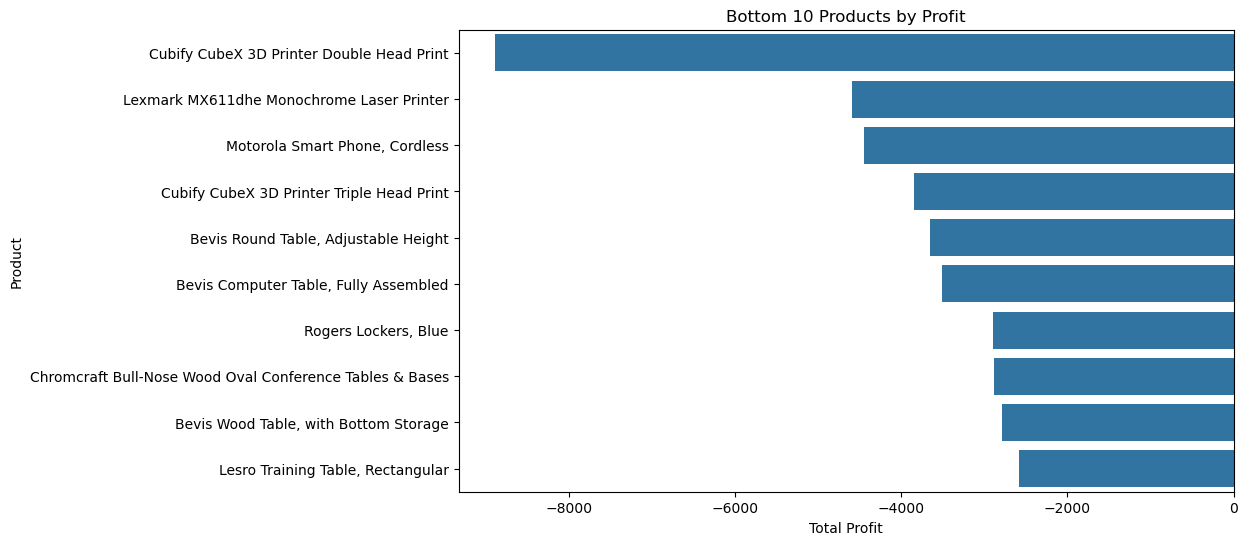

In [48]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=bottom_profit_products.reset_index(),
    x="total_profit",
    y="product_name"
)

plt.title("Bottom 10 Products by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product")
plt.show()

In [49]:
subcategory_analysis.head(10)

,total_sales,total_profit
sub_category,,
Copiers,1509439,258567.54818
Phones,1706874,216717.00580
Bookcases,1466559,161924.41950
Chairs,1501682,141973.79750
Appliances,1011081,141680.58940
Accessories,749307,129626.30620
Storage,1127124,108461.48980
Binders,461952,72449.84600
Paper,244307,59207.68270


In [50]:
subcategory_analysis.sort_values("total_profit").head(10)

,total_sales,total_profit
sub_category,,
Tables,757034,-64083.3887
Fasteners,83254,11525.4241
Labels,73433,15010.5120
Supplies,243090,22583.2631
Envelopes,170926,29601.1163
Furnishings,385609,46967.4255
Art,372163,57953.9109
Machines,779071,58867.8730
Paper,244307,59207.6827


In [51]:
top_profit_products.head(10)

,total_sales,total_profit
product_name,,
Canon imageCLASS 2200 Advanced Copier,61600,25199.9280
"Cisco Smart Phone, Full Size",76441,17238.5206
"Motorola Smart Phone, Full Size",73159,17027.1130
"Hoover Stove, Red",31664,11807.9690
"Sauder Classic Bookcase, Traditional",39110,10672.0730
"Harbour Creations Executive Leather Armchair, Adjustable",50120,10427.3260
"Nokia Smart Phone, Full Size",71904,9938.1955
"Cisco Smart Phone, with Caller ID",43124,9786.6408
"Nokia Smart Phone, with Caller ID",47880,9465.3257
